# PoC EXMODELO

## 1. IDEA 

Temporal and spatial environment : 
- Daily resolution to correctly capture hydro events, and governance actions (restrictions)
- 1D cascading system : 
  - N cascaded parcels (upstream to downstream). 
  - Water balance : each parcel receives precipitation + surface and subsurface inflow from the parcel above. The parcel then splits into evapotranspiration, soil retention, direct runoff, and pumping extraction, with remainder passing to the next parcel. 
  - Climate engine : precipitation can be AR1 process multiplied by a seasonal sine wave. The input parameter 'length of humid season' narrows or widens the peak of the sine wave. Temperature will remain static for this PoC.

The agents and behaviour : I will define 2 distinct archetypes for the upstream farmers to create behavioural contrast, alongside downstream utility/village agent.
- Upstream farmers : they will be divided using an input ratio into 2 behavioural proviles 
  - the expander, monoculture, prioritises cash crops. High water demand, steady deforestation/expansion rate, and a low rule compliance rate diring water restrictions. Their land and practice decreases soil retention and exponentially increases sediment runoff (turbidity)
  - The trad (polyculture): subsistence farming : they have lower water demands, 0 expansion, and a high rule compliance rate. Their land retains water better and contributes to negligible turbidity. 
  - Farmer dynamics : At each time step, they asses their crop water need. If there is a water restriction, their decision to pump is a probability check against their compliance rate. Yield is calculated at the end of the season based on accumulated days of water stress. 
- Downstream villagers and governance : 
  - the governance / utility agent : monitors the flow at the bottom of the chain. if the flow drops below an input minimum environmental flow, it triggers a system-wide water restriction for the next day. 
  - The villagers : they have a fixed daily drinking need. However, their access isn't just about flow volume, also water quality. The cost to make water potable scales with turbidity. 

Inputs / outputs : i want them to drastically change the system's fate :
- Core inputs : 
  - minimum environmental flow threshold (strict vs. lax governance).
  - length of the humid season (testing climate change scenarios).
  - ratio of expanders (mono) vs. trad (polyculture) farmers 
  - uptsream storage capacity (can a dam buffer the dry season?)
- Core outputs : 
  - system stress : number of water restriction days per year. 
  - Ecological failure : number of days the flow at the outlet violates the minimum environmental flow (when farmers cheat during dry season …)
  - Economic cost : downstream water treatment costs (driven by upstream turbidity). 
  - Agricultural yield : comparing the final harvest volume between the 2 farmer types. 

Feedback loops & non linear dynamics : 
- runoff-retention hydro feedback : as expanders deforest to increase land size, they increase monoculture surface. This land use change reduces the soil's capacity to act as a sponge. Consequently, wet season rain flashes immediately downstream, leaving less subsurface water to sustain the river during the dry season. This triggers earlier and more frequent water restrictions. 
- Yield vs. Cheat paradox : monoculture farmers cheat during restrictions to save their crops. However, if too many cheat, they deplete the shared subsurface flow faster, causing absolutely 0 water days later in the season. Crop yield responds non-linerarly to water : a constant 10% reduction in water is fine but 5d of 0 water causes death. 
- Turbidity tipping point (non linearity) : in real world systems like Mayotte, if turbidity crosses a certain threshold, the water treatment cannot filter it and must shut down completely. This means that during heavy rains on deforested land, downstream villagers might face a sudden water cut despite the river being completely full. 

## 2. Environmental Dynamics

### A. Precipitations

Two distinct seasons (wet and dry). Expected precipitation $\mu(t)$ is modeled as a bounded sine wave controlled by the input $L_{humid}$ (length of the humid season in days).

**Seasonality:**


$$\mu(t) = \begin{cases} P_{base} + P_{peak} \cdot \sin\left(\frac{\pi \cdot (t \bmod 365)}{L_{humid}}\right) & \text{if } (t \bmod 365) < L_{humid} \\ 0 & \text{otherwise} \end{cases}$$

**AR1 Noise:**


$$\epsilon_t = \rho \epsilon_{t-1} + \mathcal{N}(0,\sigma)$$

**Final precipitation:**


$$P(t) = \max\big[0,\, \mu(t) + \epsilon_t\big]$$

---

### B. Cascaded Hydrological Model

Each parcel $i$ separates **local soil moisture** ($S_t$) from the **passing river channel** ($Q_{in}$), ensuring upstream river flow does not artificially refill downstream soil buckets during the dry season. At each daily time step $t$, the parcel processes local rain, allows the farmer to pump, and passes the remaining flow downstream.

**1. Soil infiltration after evapotranspiration ($ET$): (temporary)**


$$S_{temp} = \max\big[0,\, S_{t-1} + P(t) - ET\big]$$

**2. Total water available to the farmer** (local soil moisture + incoming river flow $Q_{in}$ from the parcel above):


$$W_{available}(t) = S_{temp} + Q_{in}(t)$$

**3. Surface runoff and subsurface baseflow:** Water leaves the soil bucket in two ways—immediate surface runoff ($R_{surf}$) if the bucket overflows its maximum capacity $S_{max}$, and slow subsurface baseflow ($Q_{base}$) governed by drainage coefficient $\beta$:


$$R_{surf}(t) = \max\big[0,\, S_{temp} - S_{max}\big]$$

$$S_{retained} = \min\big[S_{temp},\, S_{max}\big]$$

$$Q_{base}(t) = \beta \cdot S_{retained}$$

**4. Flow to the next parcel ($Q_{out}$):** Incoming river flow combines with local runoff and baseflow, minus farmer extraction $Pump(t)$:


$$Q_{out}(t) = \max\big[0,\, Q_{in}(t) + R_{surf}(t) + Q_{base}(t) - Pump(t)\big]$$

**5. Final soil storage ($S_t$):** Remaining soil moisture after baseflow drainage (and any deficit pumping if $Pump(t)$ exceeded the river channel flow):


$$S_t = \max\Big[0,\, S_{retained} - Q_{base}(t) - \max\big(0,\, Pump(t) - [Q_{in}(t) + R_{surf}(t) + Q_{base}(t)]\big)\Big]$$

---

### C. Turbidity

Heavy rain on deforested or monoculture land washes topsoil into the river. Turbidity is modeled as a sediment concentration ($\text{Mass}/\text{Volume}$).

**Sediment generated locally:**


$$Sed_{gen}(t) = k \cdot M_i \cdot P(t)^2$$

With:

* $k$: soil erodibility constant.
* $M_i$: fraction of parcel $i$ under monoculture / deforestation.
* $P(t)^2$: quadratic rainfall term making heavy storms exponentially more destructive.

**Turbidity output:**


$$T_{out}(t) = \frac{Sed_{in}(t) + Sed_{gen}(t)}{\max\big[1.0,\, Q_{out}(t)\big]}$$

With $Sed_{in}(t)$ representing incoming sediments carried from upstream:

* The top parcel has $Sed_{in}(t) = 0$ because there is no land above it; it only generates its own $Sed_{gen}(t)$.
* Downstream, the accumulated sediment $Sed_{in}(t) + Sed_{gen}(t)$ becomes the $Sed_{in}(t)$ for the next parcel.
* The $\max[1.0,\, Q_{out}(t)]$ floor prevents artificial division-by-zero spikes when river flow approaches zero during the dry season.

## 3. Economic Dynamics

### A. Farmers behaviours 

There will be a single 'Farmer' Class that can take one of 2 profiles : Expander (monoculture) or traditionalist (polyculture). Every day, the farmers goes through a 3-steps decision process : 

The governance check (compliance) : the farmer looks at the 'water restriction' flag (Yes/No input from the downstream village). If there is a restriction, the farmer rolls a probability dice. A traditional almost always complies and stops pumping, while an expander often ignores the rule to save their thirsty crops. 

The water extraction & crop stress : if they decide to pump, theyu request their daily water demand. If the parcel's soil does not have enough water to meet this demand, the crop suffers and a 'stress_counter' increases. This represents crop_yield loss over the season. 

The expansion : Expander slowly clears surrounding land to plant more cash crops. As they do this, they directly alter the physical parameters of their parcel. They increase the monoculture ratio (which drives turbidity) and decreases the parcel's S_max (detroying the soil's availability to act as a sponge).

### B. Farmers maths 

Intended pumping $Pump_{int}$: 
- if restriction is True : $Pump_{int} = Demand$ only if a random number $r > Compliance\_Rate$, otherwise, $Pump_{int} = 0$.
- if restriction is False : $Pump_{int} = Demand$.

Actual pumping : 

$Pump_{act} = min[Pimp_{int}, S_{t-1} + Precip - Evap]$

Crop stress : If $Pump_{act} < Demand$, then $Stress = Stress+1$ (at the end of the year, high stress days = failed harvest)

Land use feedback (Expanders only) Monoculture ratio : 

$M_{ratio}(t) = \min[1.0, M_{ratio}(t-1) + \Delta_{expand}] S_{max}(t) = \max[S_{min}, S_{max}(t-1) - \Delta_{sponge}]$

### C. Village and Governance Behavioural Logic

The downstream entity acts both as the consumer (villagers needing clean drinking water) and the regulator (the governance body monitoring the river).

- The governance rule : At the end of every day, the regulator measures the final flow reaching the village. If this flow is below the 'min_environmental_flow', the regulator issues a water_restriction for the next day. This is the main signal sent back up the mountain to the farmers. 
- The treatment plant (non-linear cost) : the village takes the incoming water and treats it. The cost to make it potable scales exponentially with the incoming turbidity. 
- The turbidity tipping point : If upstream deforestation (by expanders) causes massive soil erosion during heavy rainstorm, turbidity spikes. If it crosses a critical threshold (max_turbidity_limit), the treatment plant gets clogged and must shut down entirely. On these days, the village gets 0 water, even if the river is full. 

### D. Mathematical formulation 

Safe extractable water : Before the village pumps, it substracts the environmental maximum from the incoming flow.

$Q_{safe} = max[0, Q_{in}(t) - Q_{min_env}]$

Village pumping : 

If $T_{in}(t) > T_{critical}$, the plant shuts down : $Pump_{village} = 0$
Otherwise, they take what they need : $Pump_{village} = min[Demand, Q_{safe}]$

Village Restriction indicator : 

If $Pump_{village} < Demand_{village}$, then $Village\_restriction\_days = Village\_restriction\_days+1$
This represents days the utility had to schedule water cuts (tours d'eau) to protect the river.

Water treatment cost : 

$Cost(t) = Base_Cost + \alpha (T_{in}(t))^\gamma$
Where $\alpha$ is a cost multiplier and $\gamma>1$ creates an exponential cost curve as water gets dirtier.

Governance trigger : 

Let $\delta_{critical}$ be the critical demand satisfaction threshold (ex 0.5 meaning below 50% of village demand met, there is a trigger.)
Also, $Q_{ocean} = Q_{in} - Pump_{village}$

if $Q_{ocean} < Q_{min\_env}$ **OR** $(Pump_{village} < \delta_{crit} \cdot Demand)$, it means half the demand of the village is not met, or even with the village pumping 0, the river is still failing the ecological threshold. 
This triggers : 
$Restriction(t+1) = True$ to force the upstream farmers to stop pumping tomorrow.



## 4. Assembling the modules 

They follow this timeline daily : 

- The Weather: It rains everywhere simultaneously.

- The Governance Signal: The farmers check the restriction signal broadcasted by the village at the end of yesterday.

- The Cascade (Top to Bottom): For each parcel in the chain:

- The farmer looks at the water in the soil, the rain, and the river coming from above.

- The farmer extracts their water (or complies with the restriction).

- The physical parcel calculates evaporation, updates soil moisture, and passes the remaining flow and sediment to the next parcel.

- The Village: The final flow and turbidity reach the bottom. The village attempts to treat and pump the water, and then decides if it needs to trigger a restriction for tomorrow.

The simulation is 710 days long

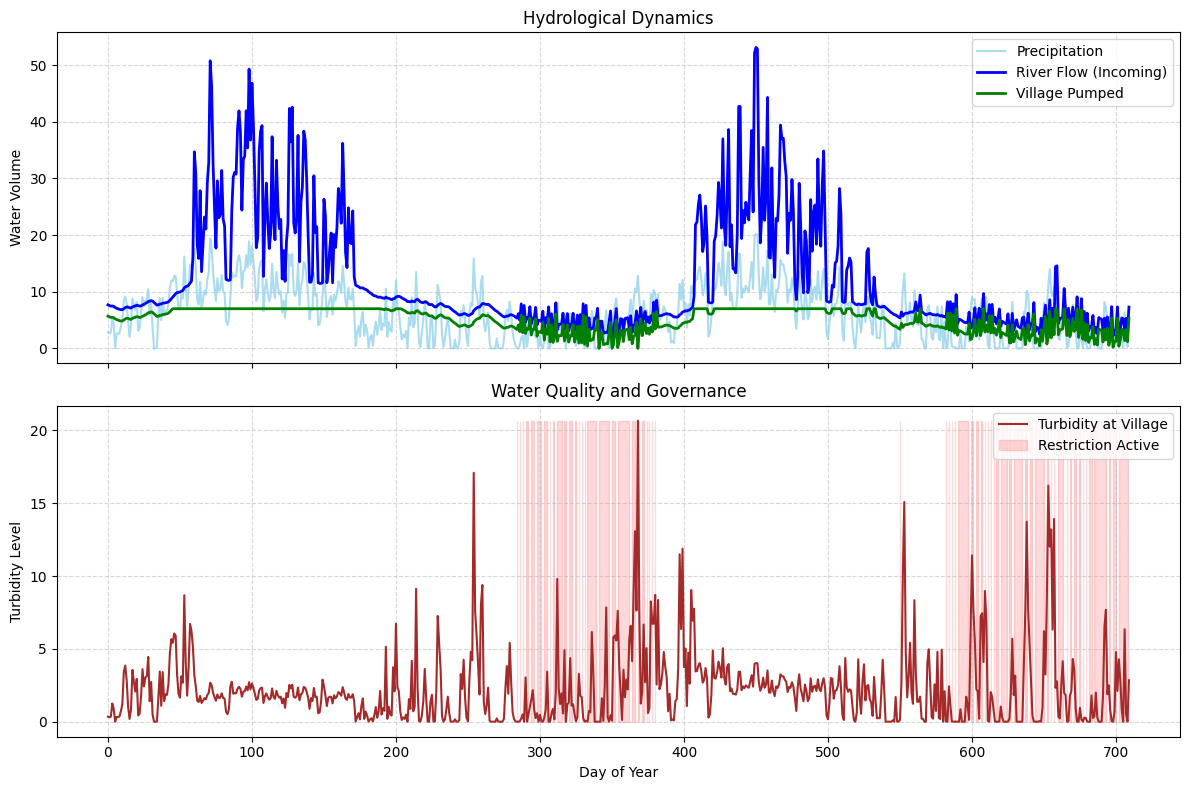


--- OPENMOLE OUTPUT DICTIONARY ---
system_stress_days: 164
eco_violations: 2
economic_treatment_cost: 3874.93
village_thirst_days: 450
yield_expander_top_pct: 93.66
yield_traditional_mid_pct: 78.03
yield_expander_bot_pct: 92.82


In [ ]:
%load_ext autoreload
%autoreload 2

from simulation import SCENARIO_INPUTS, run_simulation

results = run_simulation(SCENARIO_INPUTS, plot=True)
print(results)